# KACST Qiskit Fall Fest 2026 | Three Levels of Challenges
**Guided Hands-on · ~10 minutes **
**Joud Alshehri** · Chief Scientific Officer (CSO) · QSaudiArabia

**Predict → Code → Run → Analyze**

Companion notebook for the **Introduction to Qiskit** slides (Section 05 · Challenges, slides 30–36).
Same style as the First Quantum Circuit lesson: `QuantumRegister` → `ClassicalRegister` → `QuantumCircuit` → gates → `measure(q, c)` → `AerSimulator` → histogram.

**للمشاركين:** أكملوا أسطر `TODO` فقط ثم شغّلوا كل خلية بالترتيب (`Shift + Enter`). بعد كل تحدٍّ شغّلوا خلية التحقق ✅.

> **Simulation only.** Levels 1–2 use the ideal `AerSimulator`. Level 3 uses a simplified but real 2-qubit model of the H₂ molecule at a fixed bond length (0.735 Å); energies are *electronic* energies in Hartree (nuclear repulsion not included).

## 0 — Setup | Import the essential libraries
Run the next cell once. If packages are missing, uncomment the install line first (a kernel restart may be needed).

In [236]:
# Uncomment and run ONLY if needed in Jupyter:
# %pip install qiskit qiskit-aer matplotlib pylatexenc

In [237]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit.visualization import plot_histogram
from IPython.display import display

simulator = AerSimulator()
estimator = StatevectorEstimator()
print("Qiskit version:", qiskit.__version__)
print("✅ Environment ready")

Qiskit version: 2.6.2
✅ Environment ready


## Warm-up — Gate prediction | 1 min  *(slides 18–20)*
**Predict first**, then run. Which of these give a deterministic result, and which give ~50/50?

| Case | Gates | Your prediction |
|:--:|:--|:--|
| A | X | ? |
| B | H | ? |
| C | H → H | ? |
| D | H → Z → H | ? |

**المطلوب:** لا تعدّلوا شيئاً هنا. اكتبوا توقعكم أولاً ثم شغّلوا الخلية.

In [238]:
cases = {
    "A: X":         ["x"],
    "B: H":         ["h"],
    "C: H → H":     ["h", "h"],
    "D: H → Z → H": ["h", "z", "h"],
}
for label, gates in cases.items():
    q_w = QuantumRegister(1, "q_w")
    c_w = ClassicalRegister(1, "c_w")
    qc_w = QuantumCircuit(q_w, c_w)
    for g in gates:
        getattr(qc_w, g)(q_w[0])
    qc_w.measure(q_w, c_w)
    counts_w = simulator.run(qc_w, shots=1000).result().get_counts()
    print(f"{label:14s} → {counts_w}")

A: X           → {'1': 1000}
B: H           → {'1': 505, '0': 495}
C: H → H       → {'0': 1000}
D: H → Z → H   → {'1': 1000}


**Discuss:** Why does `H → H` give `0` every time, while `H → Z → H` gives `1`?
**تفسير:** H×H = I، فالأجزاء تتداخل وتلغي بعضها. Z تغيّر الطور فقط، لكن H بعدها تحوّل هذا الطور إلى نتيجة مختلفة: H·Z·H = X.

## Level 1 of 3 — Flip the Bit | ⏱ 1:30  *(slides 30–31)*
**Mission:** Start from `|0⟩` and make the measured result **always `1`** in the ideal simulator.

**Predict:** Which single gate flips `|0⟩` into `|1⟩`?

**المطلوب:** أضيفوا بوابة واحدة في موضع `TODO`. السجلات والدائرة والقياس جاهزة.

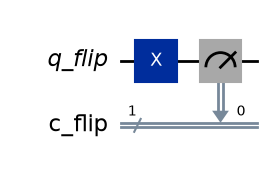

Level 1 counts: {'1': 1000}


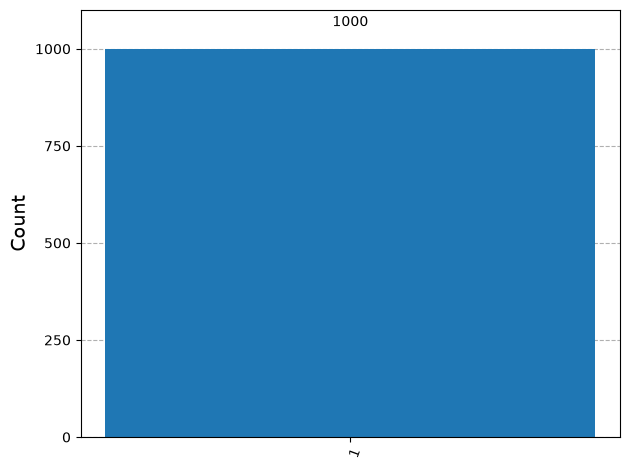

In [239]:
q_flip = QuantumRegister(1, "q_flip")
c_flip = ClassicalRegister(1, "c_flip")
qc_flip = QuantumCircuit(q_flip, c_flip)

# TODO: add ONE gate here, e.g. qc_flip.____(q_flip[0])
qc_flip.x(q_flip[0])

qc_flip.measure(q_flip, c_flip)
display(qc_flip.draw(output="mpl"))

counts_flip = simulator.run(qc_flip, shots=1000).result().get_counts()
print("Level 1 counts:", counts_flip)
display(plot_histogram(counts_flip))

In [240]:
# ✅ Self-check: in the ideal simulator, the only result should be '1'
assert counts_flip == {"1": 1000}, "Not yet! Which gate changes |0⟩ to |1⟩?"
print("✅ Level 1 passed!")

✅ Level 1 passed!


**Discuss:** Why is this output deterministic? What would you see without the gate?

## Level 2 of 3 — Entangle Three Qubits | ⏱ 2:00  *(slides 32–33)*
**Mission:** The cell already makes a Bell pair on `q[0]` and `q[1]`. Spread the entanglement to `q[2]` so that **only `000` and `111` appear** — never mixed results like `010`.

**Predict:** You need **one more gate**. Which one, and on which qubits?

**المطلوب:** أضيفوا بوابة واحدة في موضع `TODO`. تلميح: نفس نوع البوابة الذي صنع التشابك الأول.

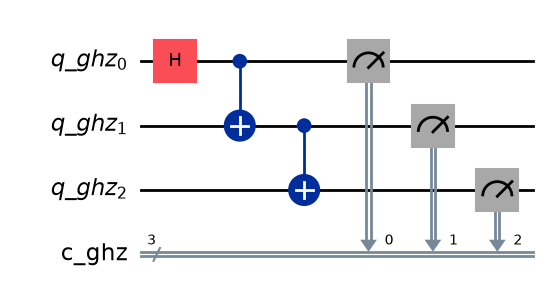

Level 2 counts: {'111': 466, '000': 534}


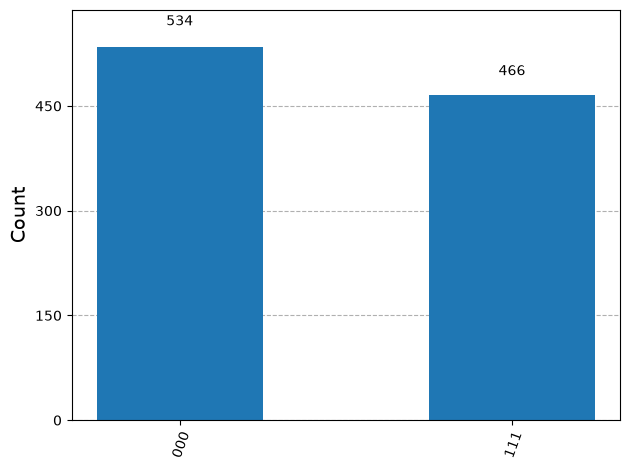

In [241]:
q_ghz = QuantumRegister(3, "q_ghz")
c_ghz = ClassicalRegister(3, "c_ghz")
qc_ghz = QuantumCircuit(q_ghz, c_ghz)

qc_ghz.h(q_ghz[0])                # superposition
qc_ghz.cx(q_ghz[0], q_ghz[1])     # entangle q0 and q1
# TODO: entangle q_ghz[2] with ONE more gate
qc_ghz.cx(q_ghz[1], q_ghz[2])

qc_ghz.measure(q_ghz, c_ghz)
display(qc_ghz.draw(output="mpl"))

counts_ghz = simulator.run(qc_ghz, shots=1000).result().get_counts()
print("Level 2 counts:", counts_ghz)
display(plot_histogram(counts_ghz))

In [242]:
# ✅ Self-check: only 000 and 111, each roughly half the time
assert set(counts_ghz) == {"000", "111"}, f"Not yet! You got {sorted(counts_ghz)}. Is q2 connected to the others?"
p000 = counts_ghz["000"] / 1000
assert 0.40 < p000 < 0.60, "Both 000 and 111 should appear about 50% of the time."
print(f"✅ Level 2 passed!  P(000) = {p000:.1%}, P(111) = {1 - p000:.1%}")

✅ Level 2 passed!  P(000) = 53.4%, P(111) = 46.6%


**Discuss:** If you measure `q0` and get `1`, what do you know about `q1` and `q2`?
**تفسير:** هذه حالة GHZ: (|000⟩ + |111⟩)/√2. الكيوبتات الثلاثة مرتبطة، فنتيجة واحد منها تحدد نتيجة الاثنين الآخرين.

## Level 3 of 3 — Energy: The Hydrogen Molecule | ⏱ 3:30  *(slides 34–36)*
Hydrogen is a clean fuel. Can a quantum computer find the **lowest energy** of an H₂ molecule?

1. **Molecule → Hamiltonian:** the energy of H₂ is written as a sum of Pauli terms.
2. **Circuit → trial state:** `RY(θ)` + `CNOT` + `X` prepare a guess for the molecule's state.
3. **Estimator → energy:** Qiskit computes the average energy ⟨H⟩ of that guess.
4. **Lowest energy wins:** change θ until the energy is as low as possible.

> Note: the **Estimator does not need `measure()`** or a `ClassicalRegister` — it computes ⟨H⟩ directly from the circuit.

### Step 1 — The H₂ Hamiltonian (given)

In [243]:
H2 = SparsePauliOp.from_list([
    ("II", -1.0524), ("IZ", 0.3979), ("ZI", -0.3979),
    ("ZZ", -0.0113), ("XX", 0.1809),
])
print(H2)

SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-1.0524+0.j,  0.3979+0.j, -0.3979+0.j, -0.0113+0.j,  0.1809+0.j])


### Step 2 — The trial circuit (given)
One angle θ controls the guess. Run once to see the circuit.

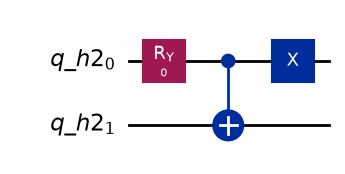

In [244]:
def h2_circuit(theta):
    q_h2 = QuantumRegister(2, "q_h2")
    qc_h2 = QuantumCircuit(q_h2)           # no ClassicalRegister needed for Estimator
    qc_h2.ry(theta, q_h2[0])
    qc_h2.cx(q_h2[0], q_h2[1])
    qc_h2.x(q_h2[0])
    return qc_h2


def energy(theta):
    result = estimator.run([(h2_circuit(theta), H2)]).result()
    return float(result[0].data.evs)


display(h2_circuit(0.0).draw(output="mpl"))

### Step 3 — The game 🎮
Start at **θ = 0** (energy ≈ −1.837 Ha). **Target: get below −1.85 Ha.**
Change `theta` and re-run this cell as many times as you like. Your best try is remembered.
Angles are in **radians** — try small positive and negative values.

**المطلوب:** غيّروا قيمة `theta` فقط وأعيدوا التشغيل. أول من يصل لطاقة أقل من −1.85 يرفع صوته!

In [245]:
try:
    my_tries
except NameError:
    my_tries = []

theta = -0.22   # TODO: try other angles! (radians)

E = energy(theta)
my_tries.append((E, theta))
best_E, best_theta = min(my_tries)
print(f"θ = {theta:+.3f}  →  Energy = {E:.4f} Ha")
print(f"Your best so far: {best_E:.4f} Ha at θ = {best_theta:+.3f}  ({len(my_tries)} tries)")

θ = -0.220  →  Energy = -1.8572 Ha
Your best so far: -1.8572 Ha at θ = -0.220  (25 tries)


In [246]:
# ✅ Self-check: did you beat the target?
best_E, best_theta = min(my_tries)
assert best_E < -1.85, f"Not yet! Best = {best_E:.4f} Ha. Try θ values between -1 and 1."
print(f"✅ Level 3 passed!  E = {best_E:.4f} Ha at θ = {best_theta:+.3f}")

✅ Level 3 passed!  E = -1.8572 Ha at θ = -0.220


**Discuss / نقاش:**
- What did we just do by hand? → The core idea of **VQE** (Variational Quantum Eigensolver).
- In real VQE, who changes θ? → A **classical optimizer**, automatically.
- Why does this matter for energy? → The same method can model molecules for **batteries, catalysts and hydrogen storage**, which are hard for classical computers.

## ⭐ Bonus (optional) — See the whole energy landscape
Let the computer try **many** angles at once and plot the energy curve. Where is the lowest point?

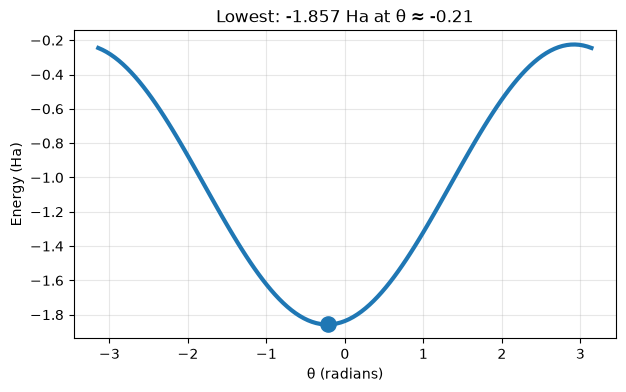

In [247]:
thetas = np.linspace(-np.pi, np.pi, 121)
energies = [energy(t) for t in thetas]
i_min = int(np.argmin(energies))

plt.figure(figsize=(7, 4))
plt.plot(thetas, energies, lw=3)
plt.scatter([thetas[i_min]], [energies[i_min]], s=120, zorder=3)
plt.xlabel("θ (radians)"); plt.ylabel("Energy (Ha)")
plt.title(f"Lowest: {energies[i_min]:.3f} Ha at θ ≈ {thetas[i_min]:.2f}")
plt.grid(alpha=0.3); plt.show()

## 🐞 Bonus (optional) — Bug hunt  *(slides 38–39)*
This cell is **supposed** to make a Bell state (only `00` and `11`), but it has **two common mistakes**. Find and fix them.

**المطلوب:** صحّحوا الخطأين ثم شغّلوا خلية التحقق.

In [248]:
q_bug = QuantumRegister(2, "q_bug")
c_bug = ClassicalRegister(2, "c_bug")
qc_bug = QuantumCircuit(q_bug, c_bug)

qc_bug.h(q_bug[0])
qc_bug.cx(q_bug[0], q_bug[1])   # FIX 1: control = q0 (the qubit in superposition), target = q1
qc_bug.measure(q_bug, c_bug)    # FIX 2: measure, otherwise there are no counts

counts_bug = simulator.run(qc_bug, shots=1000).result().get_counts()
print(counts_bug)

{'00': 509, '11': 491}


In [249]:
# ✅ Self-check
assert set(counts_bug) == {"00", "11"}, "Still buggy! Check the CNOT order and the measurement."
print("✅ Bug hunt passed!")

✅ Bug hunt passed!


## Reflection | 1 minute
1. Which gate gave a **deterministic** change, and which gave a **probability distribution**?
2. Why do we need a `ClassicalRegister` in Levels 1–2, but not in Level 3?
3. What does the GHZ state tell us about the three qubits?
4. Who changes θ in a real VQE calculation?

🎉 **Finish:** Explain one histogram — or your best energy — to your neighbour.